In [62]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [63]:
import os

os.listdir('/content/drive/MyDrive')

['Google.csv',
 'Colab Notebooks',
 'the_verdict.txt',
 'model2.pth',
 'model4.pth',
 'ai_research_assistant',
 'model1.pth']

In [64]:
import pandas as pd # importing data

file_path = '/content/drive/MyDrive/Google.csv'

data = pd.read_csv(file_path)

data.head()

,Unnamed: 0,open,high,low,close,adjclose,volume,ticker
0,2016-01-04,37.150002,37.202999,36.562901,37.091999,37.091999,65456000,GOOG
1,2016-01-05,37.322498,37.599998,36.931999,37.129002,37.129002,39014000,GOOG
2,2016-01-06,36.500000,37.359001,36.445999,37.181000,37.181000,38940000,GOOG
3,2016-01-07,36.515499,36.924999,35.952999,36.319500,36.319500,59274000,GOOG
4,2016-01-08,36.572498,36.661499,35.650002,35.723499,35.723499,49018000,GOOG


Converting data into Dataframe and Assigning 'Date' to the Unnamed column:

In [65]:
df = pd.DataFrame(data)
df

,Unnamed: 0,open,high,low,close,adjclose,volume,ticker
0,2016-01-04,37.150002,37.202999,36.562901,37.091999,37.091999,65456000,GOOG
1,2016-01-05,37.322498,37.599998,36.931999,37.129002,37.129002,39014000,GOOG
2,2016-01-06,36.500000,37.359001,36.445999,37.181000,37.181000,38940000,GOOG
3,2016-01-07,36.515499,36.924999,35.952999,36.319500,36.319500,59274000,GOOG
4,2016-01-08,36.572498,36.661499,35.650002,35.723499,35.723499,49018000,GOOG
...,...,...,...,...,...,...,...,...
2108,2024-05-20,177.309998,179.949997,177.225006,178.460007,178.460007,17495100,GOOG
2109,2024-05-21,178.399994,179.820007,177.309998,179.539993,179.539993,14706000,GOOG
2110,2024-05-22,178.399994,178.852005,176.779999,178.000000,178.000000,16189400,GOOG
2111,2024-05-23,178.779999,179.910004,174.539993,175.059998,175.059998,14928400,GOOG


In [66]:
df = df.rename(columns={'Unnamed: 0': 'date'})

df['date'] = pd.to_datetime(df['date'])

df.head()

,date,open,high,low,close,adjclose,volume,ticker
0,2016-01-04,37.150002,37.202999,36.562901,37.091999,37.091999,65456000,GOOG
1,2016-01-05,37.322498,37.599998,36.931999,37.129002,37.129002,39014000,GOOG
2,2016-01-06,36.500000,37.359001,36.445999,37.181000,37.181000,38940000,GOOG
3,2016-01-07,36.515499,36.924999,35.952999,36.319500,36.319500,59274000,GOOG
4,2016-01-08,36.572498,36.661499,35.650002,35.723499,35.723499,49018000,GOOG


In [67]:
print(df.dtypes)

date        datetime64[ns]
open               float64
high               float64
low                float64
close              float64
adjclose           float64
volume               int64
ticker              object
dtype: object


Check Time Periods

In [68]:
print("Start date: ", df['date'].min())
print("End date: ", df['date'].max())
print("Number of observations: ", len(df))

Start date:  2016-01-04 00:00:00
End date:  2024-05-24 00:00:00
Number of observations:  2113


checking whether the dates are sorted:

In [69]:
print("Dates sorted: ", df['date'].is_monotonic_increasing)

Dates sorted:  True


Checking the ticker

Since this dataset contains Google stock:

In [70]:
print(df['ticker'].value_counts())

ticker
GOOG    2113
Name: count, dtype: int64


Implementing EDA to find missing values and noises

In [71]:
print(df.shape)
print(df.columns)
print(df.info())

(2113, 8)
Index(['date', 'open', 'high', 'low', 'close', 'adjclose', 'volume', 'ticker'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2113 entries, 0 to 2112
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   date      2113 non-null   datetime64[ns]
 1   open      2113 non-null   float64       
 2   high      2113 non-null   float64       
 3   low       2113 non-null   float64       
 4   close     2113 non-null   float64       
 5   adjclose  2113 non-null   float64       
 6   volume    2113 non-null   int64         
 7   ticker    2113 non-null   object        
dtypes: datetime64[ns](1), float64(5), int64(1), object(1)
memory usage: 132.2+ KB
None


In [72]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2113 entries, 0 to 2112
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   date      2113 non-null   datetime64[ns]
 1   open      2113 non-null   float64       
 2   high      2113 non-null   float64       
 3   low       2113 non-null   float64       
 4   close     2113 non-null   float64       
 5   adjclose  2113 non-null   float64       
 6   volume    2113 non-null   int64         
 7   ticker    2113 non-null   object        
dtypes: datetime64[ns](1), float64(5), int64(1), object(1)
memory usage: 132.2+ KB


In [73]:
df.describe()

,date,open,high,low,close,adjclose,volume
count,2113,2113.000000,2113.000000,2113.000000,2113.000000,2113.000000,2.113000e+03
mean,2020-03-13 23:09:34.159962112,82.510420,83.408536,81.696887,82.576327,82.576327,3.040611e+07
min,2016-01-04 00:00:00,33.392502,33.615002,33.153000,33.412998,33.412998,6.936000e+06
25%,2018-02-07 00:00:00,52.043999,52.634998,51.264000,51.973000,51.973000,2.147350e+07
50%,2020-03-16 00:00:00,68.087502,68.879997,67.449997,68.058502,68.058502,2.663600e+07
75%,2022-04-19 00:00:00,116.760002,118.349998,115.337502,117.010498,117.010498,3.451000e+07
max,2024-05-24 00:00:00,178.779999,179.949997,177.309998,179.539993,179.539993,1.269620e+08
std,NaN,37.784157,38.224165,37.394997,37.818402,37.818402,1.406362e+07


In [74]:
df.describe(include='all')

,date,open,high,low,close,adjclose,volume,ticker
count,2113,2113.000000,2113.000000,2113.000000,2113.000000,2113.000000,2.113000e+03,2113
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GOOG
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2113
mean,2020-03-13 23:09:34.159962112,82.510420,83.408536,81.696887,82.576327,82.576327,3.040611e+07,NaN
min,2016-01-04 00:00:00,33.392502,33.615002,33.153000,33.412998,33.412998,6.936000e+06,NaN
25%,2018-02-07 00:00:00,52.043999,52.634998,51.264000,51.973000,51.973000,2.147350e+07,NaN
50%,2020-03-16 00:00:00,68.087502,68.879997,67.449997,68.058502,68.058502,2.663600e+07,NaN
75%,2022-04-19 00:00:00,116.760002,118.349998,115.337502,117.010498,117.010498,3.451000e+07,NaN
max,2024-05-24 00:00:00,178.779999,179.949997,177.309998,179.539993,179.539993,1.269620e+08,NaN


In [75]:
df.describe(include=object)

,ticker
count,2113
unique,1
top,GOOG
freq,2113


Plotting using scatter type to see the correlation among features.Also this scatter plots can show us the outliers and noises.

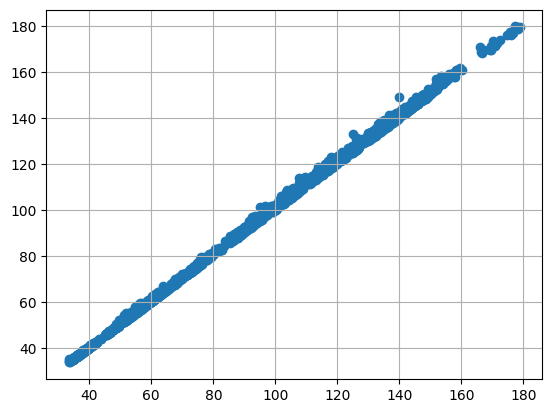

In [76]:
import matplotlib.pyplot as plt
plt.scatter(df['open'], df['high'])
plt.grid()

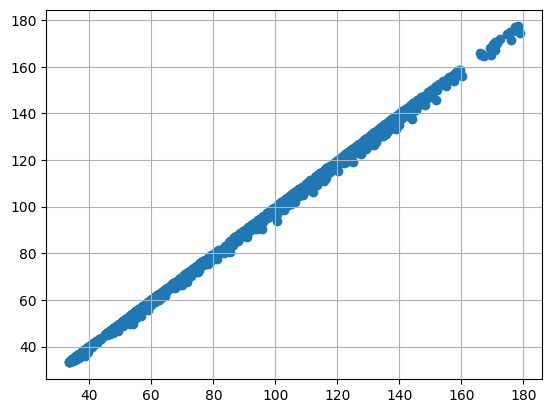

In [77]:
plt.scatter(df['open'], df['low'])
plt.grid()

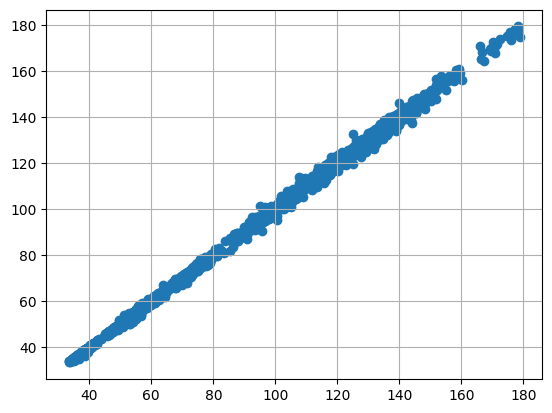

In [78]:
plt.scatter(df['open'], df['close'])
plt.grid()

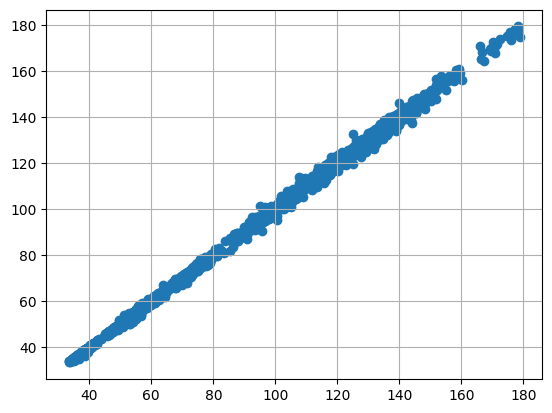

In [79]:
plt.scatter(df['open'], df['adjclose'])
plt.grid()

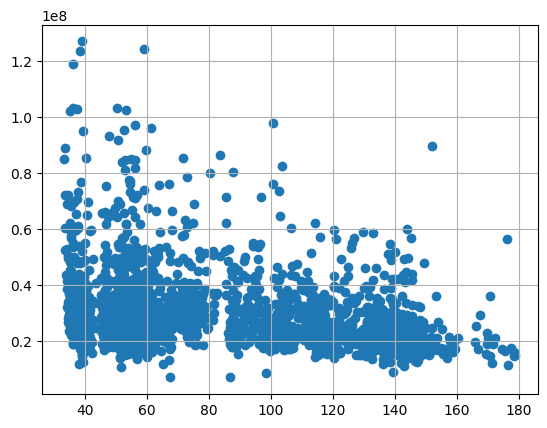

In [80]:
plt.scatter(df['open'], df['volume'])
plt.grid()

Plotting Google's closing price

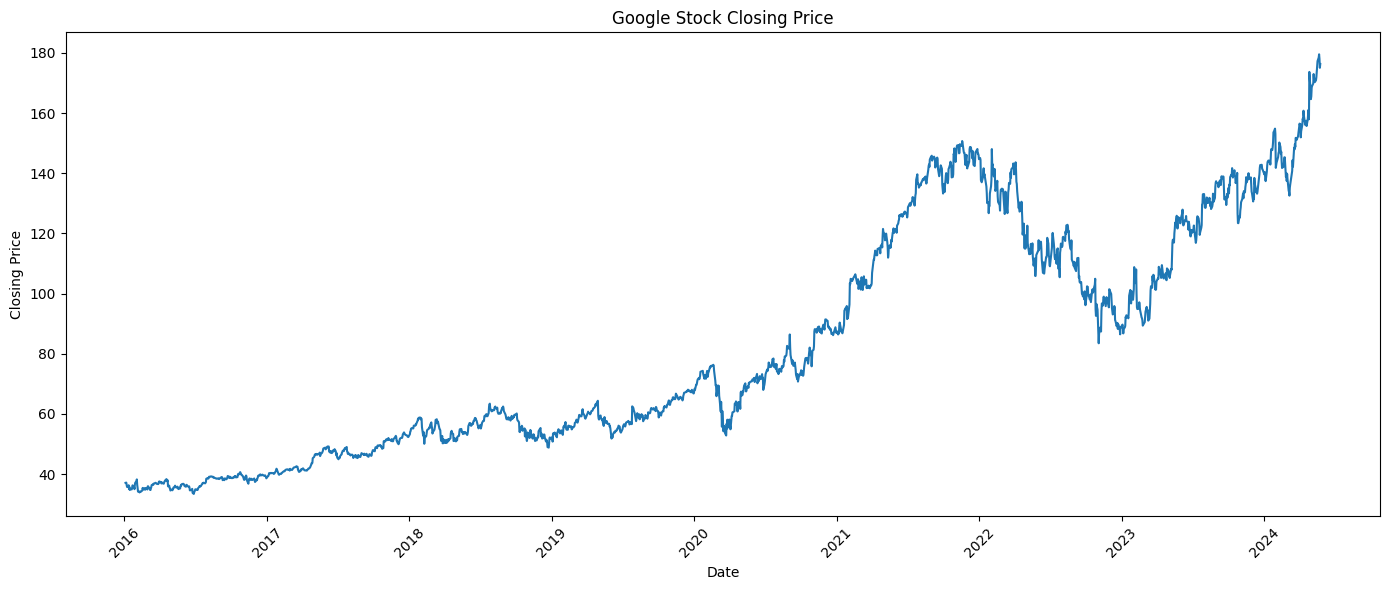

In [81]:
plt.figure(figsize=(14, 6))

plt.plot(df['date'], df['close'])

plt.title('Google Stock Closing Price')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Now, plotting all OHLC prices

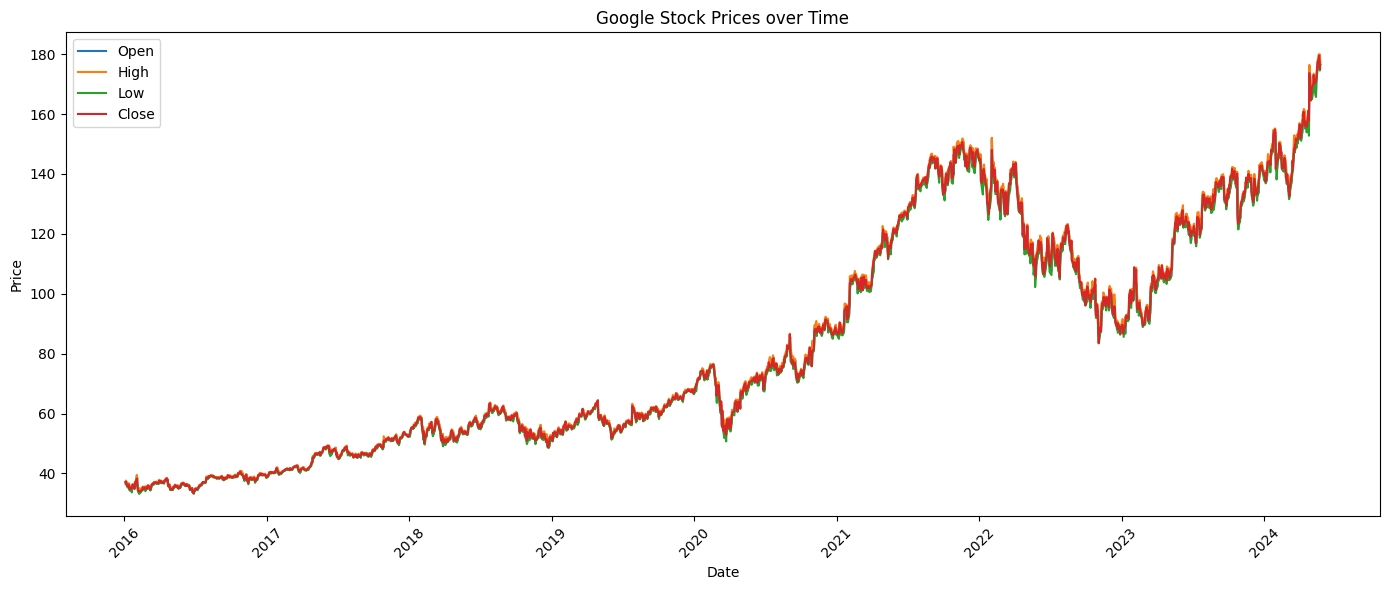

In [82]:
plt.figure(figsize=(14, 6))


plt.plot(df['date'], df['open'], label='Open')
plt.plot(df['date'], df['high'], label='High')
plt.plot(df['date'], df['low'], label='Low')
plt.plot(df['date'], df['close'], label='Close')


plt.title("Google Stock Prices over Time")
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



Trading volume

Volume is another important variable.

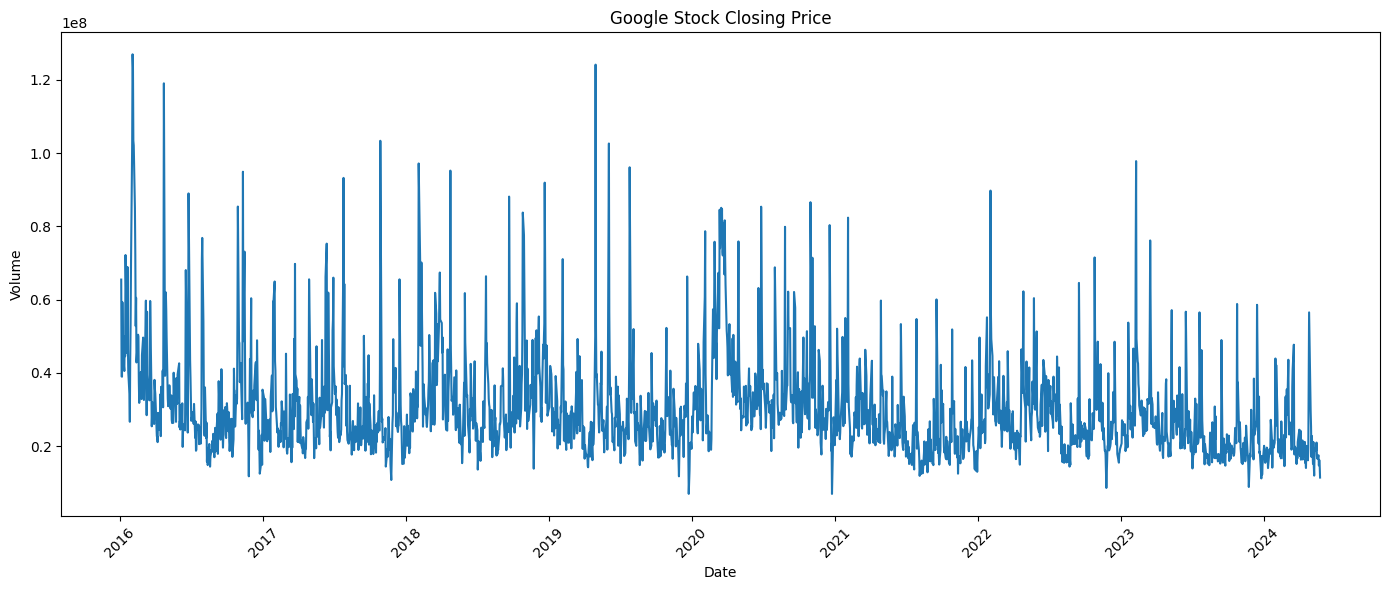

In [83]:
plt.figure(figsize=(14, 6))

plt.plot(df['date'], df['volume'])

plt.title('Google Stock Closing Price')
plt.xlabel('Date')
plt.ylabel('Volume')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Correlation analysis

For the numerical features:

In [84]:
correlation = df[
    ['open', 'high', 'low', 'close', 'adjclose', 'volume']
].corr()

print(correlation)

              open      high       low     close  adjclose    volume
open      1.000000  0.999754  0.999736  0.999426  0.999426 -0.290224
high      0.999754  1.000000  0.999694  0.999732  0.999732 -0.285989
low       0.999736  0.999694  1.000000  0.999758  0.999758 -0.298037
close     0.999426  0.999732  0.999758  1.000000  1.000000 -0.293358
adjclose  0.999426  0.999732  0.999758  1.000000  1.000000 -0.293358
volume   -0.290224 -0.285989 -0.298037 -0.293358 -0.293358  1.000000


Let's visualize it by plotting a heatmap

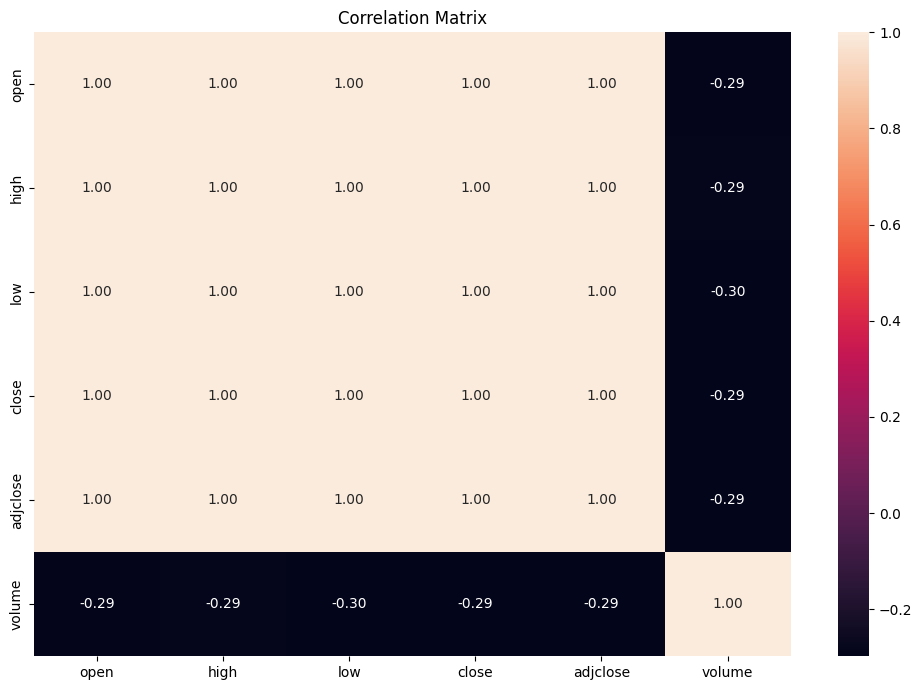

In [85]:
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f'
)


plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

One important thing we should investigate

we should check whether close = adjclose because it seems they are identical based on our data

In [86]:
print((df['close'] == df['adjclose']).all())

True


Checking for impossible values

In [87]:
print("Negative Prices:")
print((df[['open', 'high', 'close', 'low', 'adjclose']] < 0).sum())

print("\nZero volume:")
print((df["volume"] == 0).sum())


Negative Prices:
open        0
high        0
close       0
low         0
adjclose    0
dtype: int64

Zero volume:
0


Check the relationship between daily high and low

In [88]:
print("High < Low:", (df['high'] < df['low']).sum())

High < Low: 0


Check whether the dates contain duplicates

In [89]:
print("Duplicate dates: ", df['date'].duplicated().sum())

Duplicate dates:  0


Moving from EDA to Preprocessing

Our goal here is to predict the stock prices from previous data

In [90]:
features = [["open"], "high", "low", "close", "volume"]

Because close and adjclose are identical we don't need to include both of them

In [91]:
features = ['open', 'high', 'low', 'close', 'volume']

data1 = df[features].copy()

print(data1.shape)
display(data1.head())

(2113, 5)


,open,high,low,close,volume
0,37.150002,37.202999,36.562901,37.091999,65456000
1,37.322498,37.599998,36.931999,37.129002,39014000
2,36.500000,37.359001,36.445999,37.181000,38940000
3,36.515499,36.924999,35.952999,36.319500,59274000
4,36.572498,36.661499,35.650002,35.723499,49018000


Let's split the data
80% training data
20% test data

In [92]:
train_size = int(len(data1)*0.8)

train_data = data1.iloc[:train_size].copy()
test_data = data1.iloc[train_size:].copy()

print("Total data1: ", len(data1))
print("Training data: ", len(train_data))
print("Test data: ", len(test_data))

Total data1:  2113
Training data:  1690
Test data:  423


Now let's verify the dates. Since data itself doesn't contain the date, we use the original df:

In [93]:
print("Training period: ")
print(df['date'].iloc[:train_size].min())
print(df['date'].iloc[:train_size].max())

print("\n Test periods: ")
print(df['date'].iloc[train_size:].min())
print(df['date'].iloc[train_size:].max())


Training period: 
2016-01-04 00:00:00
2022-09-19 00:00:00

 Test periods: 
2022-09-20 00:00:00
2024-05-24 00:00:00


Scaling the features

We'll use MinMaxScaler, which transforms each feature approximately to the range 0–1.

Most importantly, we fit the scaler only on the training data:

In [94]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_data)
test_scaled = scaler.transform(test_data)

We use .transform fot test_data instead of .fit_transform because the test set represents the future, and using its distribution to determine the scaling would introduce information leakage.

Let's check the results

In [95]:
print("Train shape: ", train_scaled.shape)
print("Test shape: ", test_scaled.shape)

print("\n First training row: ")
print(train_scaled[0])

Train shape:  (1690, 5)
Test shape:  (423, 5)

 First training row: 
[0.03171662 0.03028229 0.02921074 0.0313651  0.48756103]


Creating sequences

Now we get to the part that makes the data suitable for an RNN.

An RNN doesn't simply receive one row at a time. It receives a sequence of observations.

We'll start with a 30-day lookback window:

Defining the sequence length

In [96]:
sequence_length = 30

Creating a function

We'll make a function so we can reuse it later:

In [97]:
import numpy as np

def create_sequences(data1, sequence_length):

  X = []
  y = []

  for i in range(sequence_length, len(data1)):
    X.append(data1[i-sequence_length:i])
    y.append(data1[i, 3]) # close is column 3

  return np.array(X), np.array(y)



Create the training sequences

In [98]:
X_train, y_train = create_sequences(
    train_scaled,
    sequence_length
)

Checking the shape:

In [99]:
print("X_train shape: ", X_train.shape)
print("y_train shape: ", y_train.shape)

X_train shape:  (1660, 30, 5)
y_train shape:  (1660,)


What about the test sequences?

There is an important detail here.

We cannot simply create test sequences using only test_scaled, because the first test prediction needs the 30 days immediately before the first test day.

So we'll take the last 30 training observations and combine them with the test observations:

In [100]:
test_input = np.concatenate(
    [train_scaled[-sequence_length:], test_scaled],
    axis=0
)

In [101]:
X_test, y_test = create_sequences(
    test_input,
    sequence_length
)

In [102]:
print("X_test shape: ", X_test.shape)
print("y_test shape: ", y_test.shape)

X_test shape:  (423, 30, 5)
y_test shape:  (423,)


Next step: convert the data to PyTorch tensors

Because we're going to build the RNN with PyTorch, we need to convert our NumPy arrays into PyTorch tensors.

In [103]:
import torch

X_train_tensor = torch.tensor(X_train, dtype = torch.float32)
y_train_tensor = torch.tensor(y_train, dtype = torch.float32)

X_test_tensor = torch.tensor(X_test, dtype = torch.float32)
y_test_tensor = torch.tensor(y_test, dtype = torch.float32)

print("X_train:", X_train_tensor.shape)
print("y_train:", y_train_tensor.shape)
print("X_test:", X_test_tensor.shape)
print("y_test:", y_test_tensor.shape)

X_train: torch.Size([1660, 30, 5])
y_train: torch.Size([1660])
X_test: torch.Size([423, 30, 5])
y_test: torch.Size([423])


Next: create DataLoaders

A DataLoader simply takes our training examples and gives them to the neural network in smaller groups called batches.

In [104]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)


batch_size = 32


train_loader = DataLoader(
    train_dataset,
    batch_size = batch_size,
    shuffle = False

)


test_loder = DataLoader(
    test_dataset,
    batch_size = batch_size,
    shuffle = False
)

Why shuffle=False?

This is a time-series problem.

We don't want to randomly rearrange our observations because the chronological order of the data matters. So we'll keep the sequences in their original order.

Now let's verify what one batch looks like:

In [105]:
X_batch, y_batch = next(iter(train_loader))


print("X batch shape: ", X_batch.shape)
print("Y batch shape: ", y_batch.shape)

X batch shape:  torch.Size([32, 30, 5])
Y batch shape:  torch.Size([32])


Define the RNN model

In [106]:
import torch.nn as nn


class RNNModel(nn.Module):
  def __init__(self, input_size, hidden_size, num_layers, output_size):
    super().__init__()

    self.rnn = nn.RNN(
        input_size=input_size,
        hidden_size=hidden_size,
        num_layers=num_layers,
        batch_first=True
    )

    self.fc = nn.Linear(hidden_size, output_size)


  def forward(self, x):
    out, hidden = self.rnn(x)


    # Take the output from the last time step

    out = out[:, -1, :]


    out = self.fc(out)

    return out



In [107]:
input_size = 5
hidden_size = 64
num_layers = 2
output_size = 1

model = RNNModel(
    input_size = input_size,
    hidden_size = hidden_size,
    num_layers = num_layers,
    output_size = output_size
)

print(model)

RNNModel(
  (rnn): RNN(5, 64, num_layers=2, batch_first=True)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


Let's not train it yet. First, we should verify that data can pass through the model and that the output has the shape we expect.

Test the model with one batch

In [108]:
X_batch, y_batch = next(iter(train_loader))

output = model(X_batch)

print("X batch shape: ", X_batch.shape)
print("Y batch shape: ", y_batch.shape)
print("Model output shape: ", output.shape)

X batch shape:  torch.Size([32, 30, 5])
Y batch shape:  torch.Size([32])
Model output shape:  torch.Size([32, 1])


 Defining Loss function and optimizer

In [109]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr = 0.001
)

Build the training loop

Now we can train the RNN. We'll start with one epoch so you can see exactly what happens before we create a full training process.

In [110]:
model.train()

for X_batch, y_batch in train_loader:


  # 1. Make predictions
  predictions = model(X_batch)


  # 2. Make target shape match prediction shape
  y_batch = y_batch.unsqueeze(1)


  # 3. Calculate the loss
  loss = criterion(predictions, y_batch)


  # 4. Clear old gradients
  optimizer.zero_grad()


  # 5. Calculate gradients
  loss.backward()


  # 6. Update the model's weights
  optimizer.step()



print("One epoch completed.")





One epoch completed.


The RNN has now completed its first training epoch.

However, that loop did not record the loss, so we don't know whether the model is actually improving. The next step is to create a proper training loop that:

trains for multiple epochs,
calculates the average training loss for each epoch,
records the losses so we can plot them later.

Proper training loop

Let's use 20 epochs for now.

In [111]:
num_epochs = 20

train_losses = []

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0

    for X_batch, y_batch in train_loader:

        # Make predictions
        predictions = model(X_batch)

        # Match target shape to prediction shape
        y_batch = y_batch.unsqueeze(1)

        # Calculate loss
        loss = criterion(predictions, y_batch)

        # Clear old gradients
        optimizer.zero_grad()

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Add this batch's loss
        running_loss += loss.item()

    # Average loss across all batches
    epoch_loss = running_loss / len(train_loader)

    train_losses.append(epoch_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.6f}")

Epoch [1/20], Loss: 0.012555
Epoch [2/20], Loss: 0.015846
Epoch [3/20], Loss: 0.014128
Epoch [4/20], Loss: 0.023430
Epoch [5/20], Loss: 0.017908
Epoch [6/20], Loss: 0.023974
Epoch [7/20], Loss: 0.036225
Epoch [8/20], Loss: 0.070959
Epoch [9/20], Loss: 0.063945
Epoch [10/20], Loss: 0.030017
Epoch [11/20], Loss: 0.056339
Epoch [12/20], Loss: 0.030706
Epoch [13/20], Loss: 0.061867
Epoch [14/20], Loss: 0.023066
Epoch [15/20], Loss: 0.033750
Epoch [16/20], Loss: 0.084779
Epoch [17/20], Loss: 0.072737
Epoch [18/20], Loss: 0.115641
Epoch [19/20], Loss: 0.031664
Epoch [20/20], Loss: 0.073239


Create the test DataLoader

In [112]:
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("Number of test batches:", len(test_loader))

Number of test batches: 14


Verify the test_dataset

In [113]:
X_test_batch, y_test_batch = next(iter(test_loader))

print("X test batch shape:", X_test_batch.shape)
print("Y test batch shape:", y_test_batch.shape)

X test batch shape: torch.Size([32, 30, 5])
Y test batch shape: torch.Size([32])


Evaluate the RNN on the test set

In [114]:
model.eval()

test_loss = 0.0

with torch.no_grad():

  for X_batch, y_batch in test_loader:

    predictions = model(X_batch)

    y_batch = y_batch.unsqueeze(1)

    loss = criterion(predictions, y_batch)

    test_loss += loss.item()


test_loss = test_loss  / len(test_loader)

print(f"Test loss: {test_loss:.6f}")


Test loss: 0.057281


Make predictions on the test set

Let's collect the model's predictions and the actual values.

In [115]:
model.eval()


all_predictions = []
all_actuals = []


with torch.no_grad():


  for X_batch, y_batch in test_loader:

    predictions = model(X_batch)


    all_predictions.extend(predictions.squeeze(1).numpy())
    all_actuals.extend(y_batch.numpy())



print("Number of predictions:", len(all_predictions))
print("Number of actual values:", len(all_actuals))

Number of predictions: 423
Number of actual values: 423


In [116]:
print("First 10 predictions:")
print(all_predictions[:10])

print("\nFirst 10 actual values:")
print(all_actuals[:10])

First 10 predictions:
[np.float32(0.6793331), np.float32(0.68457043), np.float32(0.6811908), np.float32(0.68489575), np.float32(0.6858804), np.float32(0.6865686), np.float32(0.6860132), np.float32(0.6814143), np.float32(0.681269), np.float32(0.6757103)]

First 10 actual values:
[np.float32(0.58328503), np.float32(0.56776875), np.float32(0.57254297), np.float32(0.5606074), np.float32(0.5575382), np.float32(0.5513998), np.float32(0.5739923), np.float32(0.5513998), np.float32(0.53486055), np.float32(0.5617157)]


This gives us a very useful clue.

Your first 10 predictions are around 0.92, while the actual values are around 0.55–0.58. So the model is systematically predicting values that are much too high for these test samples.

This also explains why the test loss of 0.060194 is much larger than the training loss.

However, I don't want us to start changing the RNN architecture yet. There is something important we should check first: how the train/test split was created and whether the test data was normalized using the same scaling as the training data.

Since this is a time-series project, that preprocessing matters a lot.

Checking the target distributions

In [117]:
print("Training target:")
print("Min:", y_train.min().item())
print("Max:", y_train.max().item())
print("Mean:", y_train.mean().item())

print("\nTest target:")
print("Min:", y_test.min().item())
print("Max:", y_test.max().item())
print("Mean:", y_test.mean().item())

Training target:
Min: 0.0
Max: 1.0000000000000002
Mean: 0.3375620867219235

Test target:
Min: 0.4269284464257264
Max: 1.2457969010008085
Mean: 0.7676508911815406


Let's inspect the target over time

First, tell me which column you're predicting.

In [118]:
print(data1.columns)

Index(['open', 'high', 'low', 'close', 'volume'], dtype='object')


Let's visualize the actual problem

Before changing anything, let's plot the scaled close prices and see what happened around the train/test boundary.

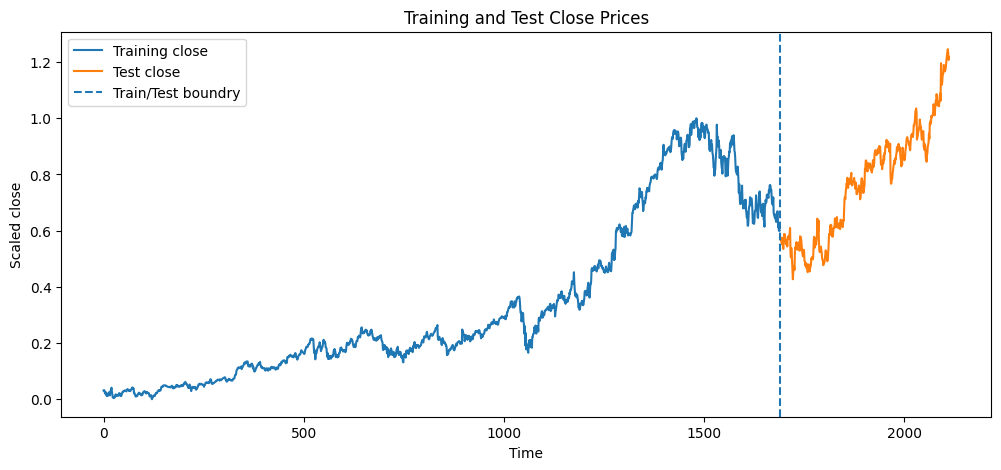

In [119]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.plot(
    train_scaled[:, 3],
    label = 'Training close'
)


plt.plot(
    range(len(train_scaled), len(train_scaled) + len(test_scaled)),
    test_scaled[:, 3],
    label = 'Test close'
)


plt.axvline(
    x = len(train_scaled),
    linestyle = '--',
    label = 'Train/Test boundry'

)


plt.xlabel("Time")
plt.ylabel("Scaled close")
plt.title("Training and Test Close Prices")
plt.legend()
plt.show()

What the plot shows

The training period (blue) ends around a scaled close value of 0.6–0.7.

Then the test period (orange):

1.Initially drops to around 0.45.
2.Recovers.
3.Then rises substantially.
4.Eventually reaches about 1.25, which is outside the entire training range.

So the model is being asked to forecast a future period where the close price eventually reaches values that it never saw as targets during training.

This explains an important part of the behavior we saw:

Training loss ≈ 0.0011

Test loss     ≈ 0.0602

and why the model was predicting around 0.92 when the first test targets were around 0.55.

There is another issue we should fix

Your current RNN predicts the absolute normalized close price:

previous 30 prices → next absolute price

For a financial time series, that can be difficult because the absolute price level changes over time. The model effectively needs to extrapolate the trend beyond the range it learned.

A more appropriate next version of this project is to predict a return/change rather than the absolute price.

For example:

Close today      = 100

Close tomorrow   = 102

Return ≈ +2%

Then the model learns:

30 previous observations

        ↓

price movement / return

        ↓

next movement


rather than trying to learn:


30 observations

        ↓
        
absolute future price

Our current baseline

We can now document it as:

Model:        Vanilla RNN

Input:        30 time steps × 5 features

Features:     open, high, low, close, volume

Target:       next close

Hidden size:  64

RNN layers:   2

Optimizer:    Adam

Learning rate: 0.001

Epochs:       20

Best training loss ≈ 0.001094

Test loss          ≈ 0.060194

Next step

Before moving to a more advanced model, let's calculate MAE and RMSE for this baseline. These are much easier to interpret than MSE loss.

In [120]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mse_1 = mean_squared_error(all_actuals, all_predictions)

mae_1 = mean_absolute_error(all_actuals, all_predictions)

rmse_1 = np.sqrt(
    mean_squared_error(all_actuals, all_predictions)
)



print(f"MAE: {mae_1:.6f}")
print(f"RMSE: {rmse_1:.6f}")

MAE: 0.180941
RMSE: 0.210538


Plot actual vs predicted values

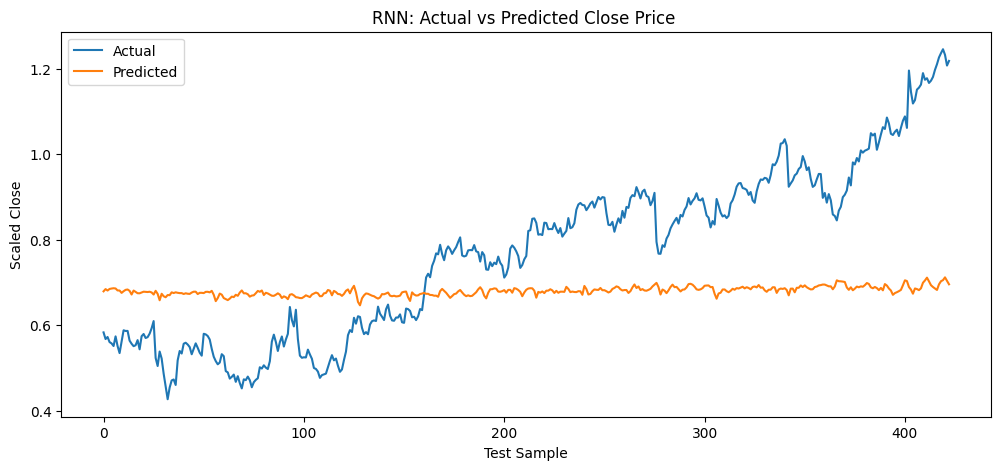

In [121]:
plt.figure(figsize=(12,5))

plt.plot(
    all_actuals,
    label="Actual"
)


plt.plot(
    all_predictions,
    label="Predicted"
)


plt.xlabel("Test Sample")
plt.ylabel("Scaled Close")
plt.title("RNN: Actual vs Predicted Close Price ")
plt.legend()
plt.show()

What the graph tells us

The blue line is the actual close price, while the orange line is the RNN prediction.

The model has learned something about the general price level, but its predictions are much too smooth:

At the beginning, actual values are around 0.45–0.60, while predictions stay around 0.78–0.80.

Around test sample 170–220, the prediction gets closer to the actual series.

Later, when the actual price rises above 1.0, the model continues to stay around 0.85–0.92.

It does not follow the sharp movements of the actual series very well.

An important observation

The model is essentially producing a smoothed estimate around the learned average/range rather than successfully forecasting the changing price level.

One correction to our earlier interpretation

We should not say that the RNN is simply "overfitting" based on the train/test loss gap alone.

The graph shows a major distribution shift between the training and test periods. The test period moves into a price range that the model did not encounter during training. That makes generalization substantially harder.

So this baseline has taught us two things:

Our RNN implementation works.

Predicting absolute close prices with this setup is difficult when the future price level moves beyond the training range.

What we should do next

I recommend that we keep this model as Model 1 / our baseline rather than modifying it immediately.

Then our next model can address one issue at a time. The natural progression is:

Model 1: Vanilla RNN — current model

Model 2: Improved RNN architecture/training

Model 3: LSTM

Model 4: GRU

Model 5: Compare the models

And separately, we can later investigate return-based forecasting rather than absolute-price forecasting.

Model 2: Improved RNN

We'll improve the baseline without changing the dataset or target. This gives us a fair comparison.

For Model 2, we'll add:

Dropout → helps reduce over-reliance on particular hidden features.

A slightly larger hidden representation: 128 units.

Keep the same 30 × 5 input.

Keep the same output: next close.

Keep Adam and the same learning rate initially.

Defining Model 2

In [122]:
class RNNModel2(nn.Module):
  def __init__(self, input_size, hidden_size, num_layers, output_size, dropout):
    super().__init__()

    self.rnn = nn.RNN(
        input_size = input_size,
        hidden_size = hidden_size,
        num_layers = num_layers,
        batch_first = True,
        dropout = dropout
    )


    self.dropout =  nn.Dropout(dropout)

    self.fc = nn.Linear(hidden_size, output_size)


  def forward(self, x):

    out, hidden = self.rnn(x)


    # Take the output from the last time step
    out = out[:, -1, :]


    out = self.dropout(out)

    out = self.fc(out)

    return out





creating the model:

In [123]:
input_size = 5
hidden_size = 128
num_layers = 2
output_size = 1
dropout = 0.2

model2 = RNNModel2(
    input_size=input_size,
    hidden_size=hidden_size,
    num_layers=num_layers,
    output_size=output_size,
    dropout=dropout
)

print(model2)

RNNModel2(
  (rnn): RNN(5, 128, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


Loss and optimizer for Model 2

In [124]:
criterion2 = nn.MSELoss()

optimizer2 = torch.optim.Adam(
    model2.parameters(),
    lr=0.001
)

Training Model 2

We'll use the same training procedure as Model 1 so the comparison is fair.

In [125]:
num_epochs = 20

train_losses_2 = []

for epoch in range(num_epochs):

    model2.train()

    running_loss = 0.0

    for X_batch, y_batch in train_loader:

        # Make predictions
        predictions = model2(X_batch)

        # Match target shape
        y_batch = y_batch.unsqueeze(1)

        # Calculate loss
        loss = criterion2(predictions, y_batch)

        # Clear old gradients
        optimizer2.zero_grad()

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer2.step()

        # Accumulate loss
        running_loss += loss.item()

    # Average loss for this epoch
    epoch_loss = running_loss / len(train_loader)

    train_losses_2.append(epoch_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss:.6f}")

Epoch [1/20], Loss: 0.004949
Epoch [2/20], Loss: 0.015146
Epoch [3/20], Loss: 0.014865
Epoch [4/20], Loss: 0.011689
Epoch [5/20], Loss: 0.008037
Epoch [6/20], Loss: 0.006930
Epoch [7/20], Loss: 0.004282
Epoch [8/20], Loss: 0.002792
Epoch [9/20], Loss: 0.001418
Epoch [10/20], Loss: 0.001354
Epoch [11/20], Loss: 0.001073
Epoch [12/20], Loss: 0.001098
Epoch [13/20], Loss: 0.001076
Epoch [14/20], Loss: 0.001263
Epoch [15/20], Loss: 0.001059
Epoch [16/20], Loss: 0.000941
Epoch [17/20], Loss: 0.001232
Epoch [18/20], Loss: 0.001043
Epoch [19/20], Loss: 0.001085
Epoch [20/20], Loss: 0.001066


Evaluating Model 2

In [126]:
model2.eval()

test_loss_2 = 0.0

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        predictions = model2(X_batch)

        y_batch = y_batch.unsqueeze(1)

        loss = criterion2(predictions, y_batch)

        test_loss_2 += loss.item()

test_loss_2 = test_loss_2 / len(test_loader)

print(f"Model 2 Test Loss: {test_loss_2:.6f}")

Model 2 Test Loss: 0.025993


Generating Model 2 predictions

In [127]:
model2.eval()

all_predictions_2 = []
all_actuals_2 = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        predictions = model2(X_batch)

        all_predictions_2.extend(
            predictions.squeeze(1).numpy()
        )

        all_actuals_2.extend(
            y_batch.numpy()
        )

print("Number of predictions:", len(all_predictions_2))
print("Number of actual values:", len(all_actuals_2))

Number of predictions: 423
Number of actual values: 423


calculating the two metrics:

In [128]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae_2 = mean_absolute_error(
    all_actuals_2,
    all_predictions_2
)

rmse_2 = np.sqrt(
    mean_squared_error(
        all_actuals_2,
        all_predictions_2
    )
)

print(f"Model 2 MAE:  {mae_2:.6f}")
print(f"Model 2 RMSE: {rmse_2:.6f}")

Model 2 MAE:  0.108914
Model 2 RMSE: 0.140824


Checking Model 2 predictions

In [129]:
print("First 10 Model 2 predictions:")
print(all_predictions_2[:10])

print("\nFirst 10 actual values:")
print(all_actuals_2[:10])

First 10 Model 2 predictions:
[np.float32(0.58428824), np.float32(0.5800139), np.float32(0.57457554), np.float32(0.5701878), np.float32(0.5642264), np.float32(0.5600033), np.float32(0.55812585), np.float32(0.56109416), np.float32(0.55800223), np.float32(0.551677)]

First 10 actual values:
[np.float32(0.58328503), np.float32(0.56776875), np.float32(0.57254297), np.float32(0.5606074), np.float32(0.5575382), np.float32(0.5513998), np.float32(0.5739923), np.float32(0.5513998), np.float32(0.53486055), np.float32(0.5617157)]


In [130]:
print("Model 2 prediction range:")
print("Min:", min(all_predictions_2))
print("Max:", max(all_predictions_2))

print("\nActual range:")
print("Min:", min(all_actuals_2))
print("Max:", max(all_actuals_2))

Model 2 prediction range:
Min: 0.4774936
Max: 0.8714113

Actual range:
Min: 0.42692846
Max: 1.2457969


Calculating MSE directly

In [131]:
from sklearn.metrics import mean_squared_error

mse_2 = mean_squared_error(
    all_actuals_2,
    all_predictions_2
)

rmse_2_check = np.sqrt(mse_2)

print(f"Model 2 MSE:  {mse_2:.6f}")
print(f"Model 2 RMSE: {rmse_2_check:.6f}")

Model 2 MSE:  0.019831
Model 2 RMSE: 0.140824


Recalculating Model 1 metrics

In [132]:
mse_1 = mean_squared_error(
    all_actuals,
    all_predictions
)

rmse_1_check = np.sqrt(mse_1)

mae_1_check = mean_absolute_error(
    all_actuals,
    all_predictions
)

print(f"Model 1 MSE:  {mse_1:.6f}")
print(f"Model 1 MAE:  {mae_1_check:.6f}")
print(f"Model 1 RMSE: {rmse_1_check:.6f}")

Model 1 MSE:  0.044326
Model 1 MAE:  0.180941
Model 1 RMSE: 0.210538


visualize Model 2

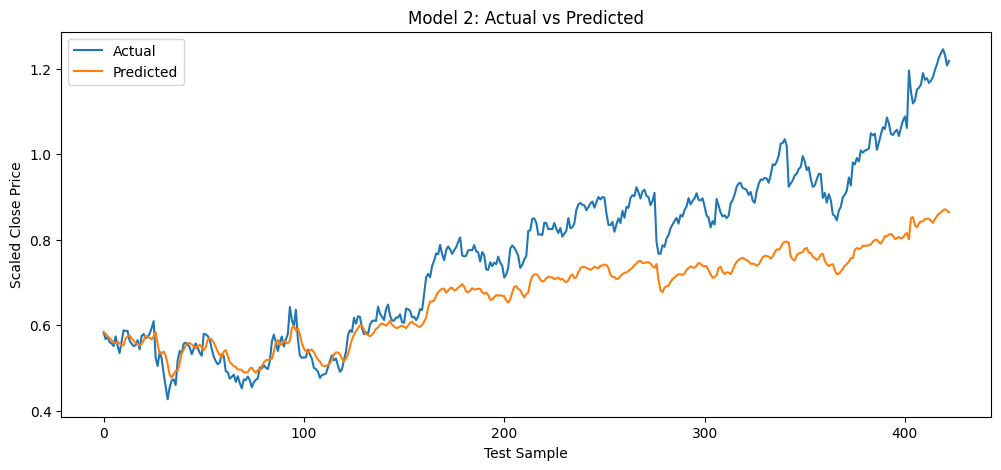

In [133]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(all_actuals_2, label="Actual")
plt.plot(all_predictions_2, label="Predicted")

plt.title("Model 2: Actual vs Predicted")
plt.xlabel("Test Sample")
plt.ylabel("Scaled Close Price")
plt.legend()
plt.show()

Comparing Model 1 and Model 2 visually

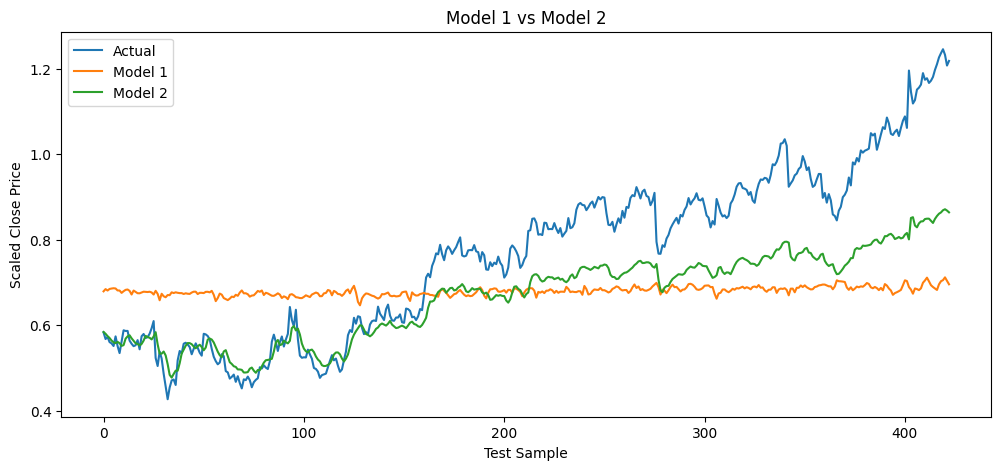

In [134]:
plt.figure(figsize=(12, 5))

plt.plot(all_actuals_2, label="Actual")
plt.plot(all_predictions, label="Model 1")
plt.plot(all_predictions_2, label="Model 2")

plt.title("Model 1 vs Model 2")
plt.xlabel("Test Sample")
plt.ylabel("Scaled Close Price")
plt.legend()
plt.show()

The plot is clear. We can now interpret the two models.

What we see

Actual: The price rises substantially throughout the test period, eventually reaching about 1.24.

Model 1: Stays almost completely flat around 0.48–0.52. It fails to follow the overall upward movement.

Model 2: Performs better. It follows the general upward direction from roughly 0.60 to 0.78, although it still substantially underestimates the actual values later in the test period.

So Model 2 is an improvement over Model 1, but neither model captures the large distribution shift in the later test period.

This also explains why Model 2's MAE/RMSE are lower than Model 1's: its predictions are generally closer to the actual series.

One important lesson

The problem isn't simply that Model 1 or Model 2 is "bad." Our test set contains values up to 1.246, while the model was trained on a target range of approximately 0–1.

Because we fitted the MinMaxScaler only on the training data, the test values above 1 are legitimate. They represent prices outside the training range.

This is an important time-series forecasting issue: the model is being asked to extrapolate beyond the range it saw during training.

Saving our Model 2 results

In [135]:
results = {
    "Model 1": {
        "MSE": mse_1,
        "MAE": mae_1_check,
        "RMSE": rmse_1_check
    },
    "Model 2": {
        "MSE": mse_2,
        "MAE": mae_2,
        "RMSE": rmse_2
    }
}

print(results)

{'Model 1': {'MSE': 0.044326106672335684, 'MAE': 0.18094144278947907, 'RMSE': np.float64(0.21053766093584228)}, 'Model 2': {'MSE': 0.019831280801256932, 'MAE': 0.10891434775740261, 'RMSE': np.float64(0.1408235804162674)}}


Model 3 — LSTM

Defining Model 3

In [136]:
class LSTMModel(nn.Module):
  def __init__(self, input_size, hidden_size, num_layers, output_size, dropout):
    super().__init__()



    self.lstm = nn.LSTM(
        input_size=input_size,
        hidden_size=hidden_size,
        num_layers=num_layers,
        batch_first=True,
        dropout=dropout
    )


    self.dropout=nn.Dropout(dropout)


    self.fc = nn.Linear(
        hidden_size,
        output_size
        )


  def forward(self, x):

    out, (hidden, cell) = self.lstm(x)

    out = out[:, -1, :]

    out = self.dropout(out)

    out = self.fc(out)


    return out

Creating Model 3

In [137]:
input_size = 5
hidden_size = 128
num_layers = 2
output_size = 1
dropout = 0.2


model3 = LSTMModel(
    input_size=input_size,
    hidden_size=hidden_size,
    num_layers=num_layers,
    output_size=output_size,
    dropout=dropout
)

print(model3)


LSTMModel(
  (lstm): LSTM(5, 128, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


Loss and optimizer

In [138]:
criterion3 = nn.MSELoss()

optimizer3 = torch.optim.Adam(
    model3.parameters(),
    lr = 0.001
)

Training Model 3

In [139]:
num_epochs = 20

train_losses_3 = []

for epoch in range(num_epochs):

  model3.train()

  running_loss = 0.0

  for X_batch, y_batch in train_loader:


    predictions = model3(X_batch)

    y_batch = y_batch.unsqueeze(1)

    loss = criterion3(
        predictions,
        y_batch
    )

    optimizer3.zero_grad()

    loss.backward()

    optimizer3.step()

    running_loss += loss.item()


  epoch_loss =running_loss / len(train_loader)


  train_losses_3.append(epoch_loss)

  print(f"Epoch [{epoch+1}/{num_epochs}], "
       f"Loss: {epoch_loss:.6f}"

       )





Epoch [1/20], Loss: 0.002758
Epoch [2/20], Loss: 0.019478
Epoch [3/20], Loss: 0.038547
Epoch [4/20], Loss: 0.050551
Epoch [5/20], Loss: 0.019405
Epoch [6/20], Loss: 0.006385
Epoch [7/20], Loss: 0.009400
Epoch [8/20], Loss: 0.004340
Epoch [9/20], Loss: 0.003670
Epoch [10/20], Loss: 0.003328
Epoch [11/20], Loss: 0.003573
Epoch [12/20], Loss: 0.003389
Epoch [13/20], Loss: 0.003616
Epoch [14/20], Loss: 0.003516
Epoch [15/20], Loss: 0.003965
Epoch [16/20], Loss: 0.003734
Epoch [17/20], Loss: 0.003621
Epoch [18/20], Loss: 0.003793
Epoch [19/20], Loss: 0.003265
Epoch [20/20], Loss: 0.003014


Model 3 Evaluation

Test loss

In [140]:
model.eval()

test_loss_3 = 0.0

with torch.no_grad():

  for X_batch, y_batch in test_loader:

    predictions = model3(X_batch)

    y_batch = y_batch.unsqueeze(1)


    loss = criterion3(
        predictions,
        y_batch
    )


    test_loss_3 += loss.item()


test_loss_3 = test_loss_3 / len(test_loader)


print(f"Model 3 Test Loss : {test_loss_3:.6f}")



Model 3 Test Loss : 0.009484


Generating predictions

In [141]:
model3.eval()

all_predictions_3 = []
all_actuals_3 = []


with torch.no_grad():

  for X_batch, y_batch in test_loader:

    predictions = model3(X_batch)

    all_predictions_3.extend(
        predictions.squeeze(1).numpy()
    )

    all_actuals_3.extend(
        y_batch.numpy()
    )


print("Number of predictions: ", len(all_predictions_3))
print("Number of actual values"), len(all_actuals_3)


Number of predictions:  423
Number of actual values


(None, 423)

Calculating MSE, MAE and RMSE

In [142]:
mse_3 = mean_squared_error(
    all_actuals_3,
    all_predictions_3
)


mae_3 = mean_absolute_error(
    all_actuals_3,
    all_predictions_3
)


rmse_3 = np.sqrt(mse_3)


print(f" Model 3 MSE:  {mse_3:.6f}")
print(f" Model 3 MAE:  {mae_3:.6f}")
print(f" Model 3 RMSE:  {rmse_3:.6f}")

 Model 3 MSE:  0.006824
 Model 3 MAE:  0.070618
 Model 3 RMSE:  0.082608


Prediction range

In [143]:
print("Model e prediction rage: ")
print("Min: ", min(all_predictions_3))
print("Max: ", max(all_predictions_3))

print("\nActual range: ")
print("Min: ", min(all_actuals_3))
print("Maxn: ", max(all_actuals_3))

Model e prediction rage: 
Min:  0.56282455
Max:  1.0839157

Actual range: 
Min:  0.42692846
Maxn:  1.2457969


Plotting Model 3

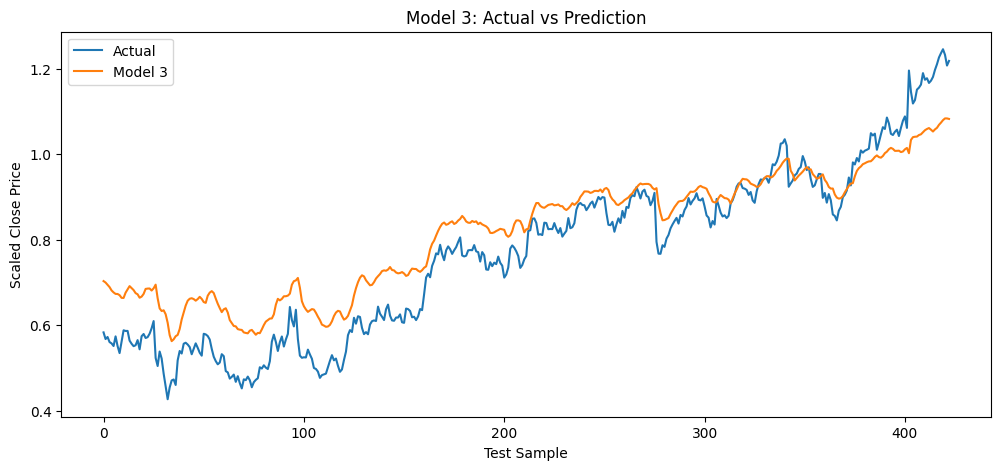

In [144]:
plt.figure(figsize=(12,5))

plt.plot(
    all_actuals_3,
    label="Actual"
)


plt.plot(
    all_predictions_3,
    label="Model 3"
)

plt.title("Model 3: Actual vs Prediction")
plt.xlabel("Test Sample")
plt.ylabel("Scaled Close Price")
plt.legend()
plt.show()

Model 4 — GRU

Defining Model 4

In [145]:
class GRUModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size, dropout):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.dropout = nn.Dropout(dropout)

        self.fc = nn.Linear(
            hidden_size,
            output_size
        )

    def forward(self, x):

        out, hidden = self.gru(x)

        out = out[:, -1, :]

        out = self.dropout(out)

        out = self.fc(out)

        return out

Creating Model 4

In [146]:
input_size = 5
hidden_size = 128
num_layers = 2
output_size = 1
dropout = 0.2

model4 = GRUModel(
    input_size=input_size,
    hidden_size=hidden_size,
    num_layers=num_layers,
    output_size=output_size,
    dropout=dropout
)

print(model4)

GRUModel(
  (gru): GRU(5, 128, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=128, out_features=1, bias=True)
)


Loss and optimizer

In [147]:
criterion4 = nn.MSELoss()

optimizer4 = torch.optim.Adam(
    model4.parameters(),
    lr=0.001
)

Training Model 4

In [148]:
num_epochs = 20

train_losses_4 = []

for epoch in range(num_epochs):

    model4.train()

    running_loss = 0.0

    for X_batch, y_batch in train_loader:

        predictions = model4(X_batch)

        y_batch = y_batch.unsqueeze(1)

        loss = criterion4(
            predictions,
            y_batch
        )

        optimizer4.zero_grad()

        loss.backward()

        optimizer4.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)

    train_losses_4.append(epoch_loss)

    print(
        f"Epoch [{epoch+1}/{num_epochs}], "
        f"Loss: {epoch_loss:.6f}"
    )

Epoch [1/20], Loss: 0.003136
Epoch [2/20], Loss: 0.013643
Epoch [3/20], Loss: 0.012245
Epoch [4/20], Loss: 0.009136
Epoch [5/20], Loss: 0.005771
Epoch [6/20], Loss: 0.002422
Epoch [7/20], Loss: 0.001196
Epoch [8/20], Loss: 0.001163
Epoch [9/20], Loss: 0.001015
Epoch [10/20], Loss: 0.000996
Epoch [11/20], Loss: 0.001201
Epoch [12/20], Loss: 0.002213
Epoch [13/20], Loss: 0.005167
Epoch [14/20], Loss: 0.003334
Epoch [15/20], Loss: 0.011873
Epoch [16/20], Loss: 0.006522
Epoch [17/20], Loss: 0.016784
Epoch [18/20], Loss: 0.008284
Epoch [19/20], Loss: 0.019622
Epoch [20/20], Loss: 0.022110


Model 4 Evaluation

Test loss

In [149]:
model4.eval()

test_loss_4 = 0.0

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        predictions = model4(X_batch)

        y_batch = y_batch.unsqueeze(1)

        loss = criterion4(
            predictions,
            y_batch
        )

        test_loss_4 += loss.item()

test_loss_4 = test_loss_4 / len(test_loader)

print(f"Model 4 Test Loss: {test_loss_4:.6f}")

Model 4 Test Loss: 0.028767


Generating predictions

In [150]:
model4.eval()

all_predictions_4 = []
all_actuals_4 = []

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        predictions = model4(X_batch)

        all_predictions_4.extend(
            predictions.squeeze(1).numpy()
        )

        all_actuals_4.extend(
            y_batch.numpy()
        )

print("Number of predictions:", len(all_predictions_4))
print("Number of actual values:", len(all_actuals_4))

Number of predictions: 423
Number of actual values: 423


Calculating metrics

In [151]:
mse_4 = mean_squared_error(
    all_actuals_4,
    all_predictions_4
)

mae_4 = mean_absolute_error(
    all_actuals_4,
    all_predictions_4
)

rmse_4 = np.sqrt(mse_4)

print(f"Model 4 MSE:  {mse_4:.6f}")
print(f"Model 4 MAE:  {mae_4:.6f}")
print(f"Model 4 RMSE: {rmse_4:.6f}")

Model 4 MSE:  0.023767
Model 4 MAE:  0.133033
Model 4 RMSE: 0.154164


Plotting Model 4

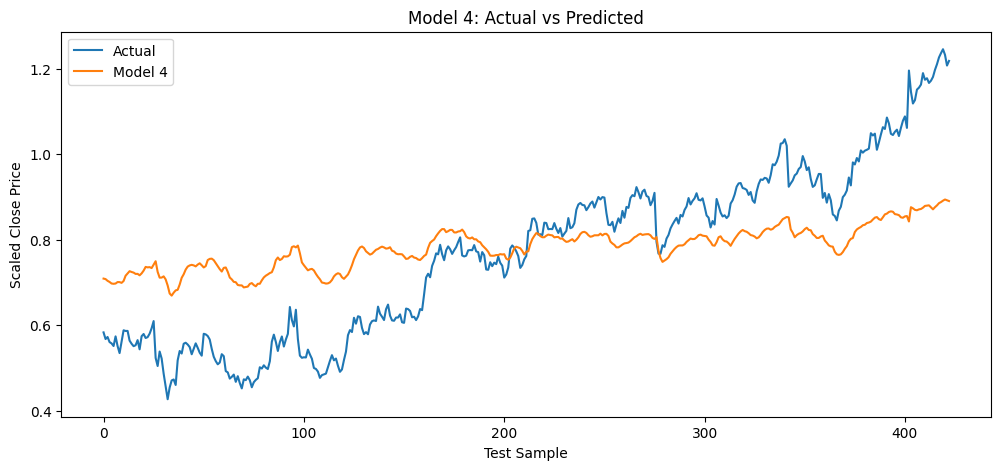

In [152]:
plt.figure(figsize=(12, 5))

plt.plot(
    all_actuals_4,
    label="Actual"
)

plt.plot(
    all_predictions_4,
    label="Model 4"
)

plt.title("Model 4: Actual vs Predicted")
plt.xlabel("Test Sample")
plt.ylabel("Scaled Close Price")
plt.legend()

plt.show()

Model 5 — Bidirectional LSTM

Defining Model 5

In [153]:
class BiLSTMModel(nn.Module):
  def __init__(self, input_size, hidden_size, num_layers, output_size, dropout ):
    super().__init__()


    self.lstm = nn.LSTM(
        input_size=input_size,
        hidden_size=hidden_size,
        num_layers=num_layers,
        batch_first=True,
        dropout=dropout,
        bidirectional=True


    )

    self.dropout = nn.Dropout(dropout)

    self.fc = nn.Linear(
        hidden_size * 2,
        output_size
    )

  def forward(self, x):

    out, (hidden,cell) = self.lstm(x)

    out = out[:, -1, :]

    out = self.dropout(out)

    out = self.fc(out)


    return out


Notice this important difference:

hidden_size * 2

because the bidirectional LSTM produces:

forward hidden state
+
backward hidden state

Creating Model 5

In [154]:
input_size = 5
hidden_sizze = 128
num_layers = 2
output_size = 1
dropout = 0.2

model5 = BiLSTMModel(
    input_size = input_size,
    hidden_size = hidden_size,
    num_layers = num_layers,
    output_size = output_size,
    dropout = dropout
)


print(model5)

BiLSTMModel(
  (lstm): LSTM(5, 128, num_layers=2, batch_first=True, dropout=0.2, bidirectional=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=256, out_features=1, bias=True)
)


Loss and optimizer

In [155]:
criterion5 = nn.MSELoss()

optimizer5 = torch.optim.Adam(
    model5.parameters(),
    lr = 0.001
)

In [156]:

input_size = 5
hidden_size = 128
num_layers = 2
output_size = 1
dropout = 0.2

model5 = BiLSTMModel(
    input_size = input_size,
    hidden_size = hidden_size,
    num_layers = num_layers,
    output_size = output_size,
    dropout = dropout
)

criterion5 = nn.MSELoss()
optimizer5 = torch.optim.Adam(model5.parameters(), lr=0.001)


print(model5)

BiLSTMModel(
  (lstm): LSTM(5, 128, num_layers=2, batch_first=True, dropout=0.2, bidirectional=True)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=256, out_features=1, bias=True)
)


Training Model 5

In [157]:
num_epochs = 20

train_losses_5 = []

for epoch in range(num_epochs):

  model5.train()

  running_loss = 0.0

  for X_batch, y_batch in train_loader:

    predictions = model5(X_batch)

    y_batch = y_batch.unsqueeze(1)

    loss = criterion5(
        predictions,
        y_batch
    )

    optimizer5.zero_grad()

    loss.backward()

    optimizer5.step()

    running_loss += loss.item()

  epoch_loss = running_loss / len(train_loader)

  train_losses_5.append(epoch_loss)

  print(
      f"Epoch [{epoch+1} / {num_epochs}], "
      f"Loss: {epoch_loss:.6f}"
  )

Epoch [1 / 20], Loss: 0.003264
Epoch [2 / 20], Loss: 0.018914
Epoch [3 / 20], Loss: 0.028905
Epoch [4 / 20], Loss: 0.042516
Epoch [5 / 20], Loss: 0.037697
Epoch [6 / 20], Loss: 0.016077
Epoch [7 / 20], Loss: 0.001754
Epoch [8 / 20], Loss: 0.001709
Epoch [9 / 20], Loss: 0.001690
Epoch [10 / 20], Loss: 0.001493
Epoch [11 / 20], Loss: 0.001754
Epoch [12 / 20], Loss: 0.001796
Epoch [13 / 20], Loss: 0.001988
Epoch [14 / 20], Loss: 0.002309
Epoch [15 / 20], Loss: 0.002715
Epoch [16 / 20], Loss: 0.003013
Epoch [17 / 20], Loss: 0.003159
Epoch [18 / 20], Loss: 0.002740
Epoch [19 / 20], Loss: 0.003171
Epoch [20 / 20], Loss: 0.003401


Model 5 Evaluation

Test loss

In [158]:
model5.eval()

test_loss_5 = 0.0

with torch.no_grad():
  for X_batch, y_batch in test_loader:

    predictions = model5(X_batch)

    y_batch = y_batch.unsqueeze(1)

    loss = criterion5(
        predictions,
        y_batch

    )


    test_loss_5 += loss.item()


test_loss_5 = test_loss_5 / len(test_loader)

print(f"Model 5 Test Loss: {test_loss:.6f}")



Model 5 Test Loss: 0.057281


Generating predictions

In [159]:
model5.eval()

all_predictions_5 = []
all_actuals_5 = []


with torch.no_grad():

  for X_batch, y_batch in test_loader:

    predictions = model5(X_batch)

    all_predictions_5.extend(
        predictions.squeeze(1).numpy()
    )


    all_actuals_5.extend(
        y_batch.numpy()
    )



print("Number of Predictions: ", len(all_predictions_5))
print("Number of Actual Values: ", len(all_actuals_5))

Number of Predictions:  423
Number of Actual Values:  423


Calculating metrics

In [160]:
mse_5 = mean_squared_error(
    all_actuals_5,
    all_predictions_5

)


mae_5 = mean_absolute_error(
    all_actuals_5,
    all_predictions_5

)


rmse_5 = np.sqrt(mse_5)

print(f"Model 5 MSE: {mse_5:.6f}")
print(f"Model 5 MAE: {mae_5:.6f}")
print(f"Model 5 RMSE: {rmse_5:.6f}")

Model 5 MSE: 0.008119
Model 5 MAE: 0.079902
Model 5 RMSE: 0.090105


Prediction range

In [161]:
print("Model 5 prediction 5:")
print("Min:", min(all_predictions_5))
print("Max:", max(all_predictions_5))

print("\nActual range:")
print("Min:", min(all_actuals_5))
print("Max:", max(all_actuals_5))

Model 5 prediction 5:
Min: 0.5659709
Max: 1.1327336

Actual range:
Min: 0.42692846
Max: 1.2457969


Plotting Model 5

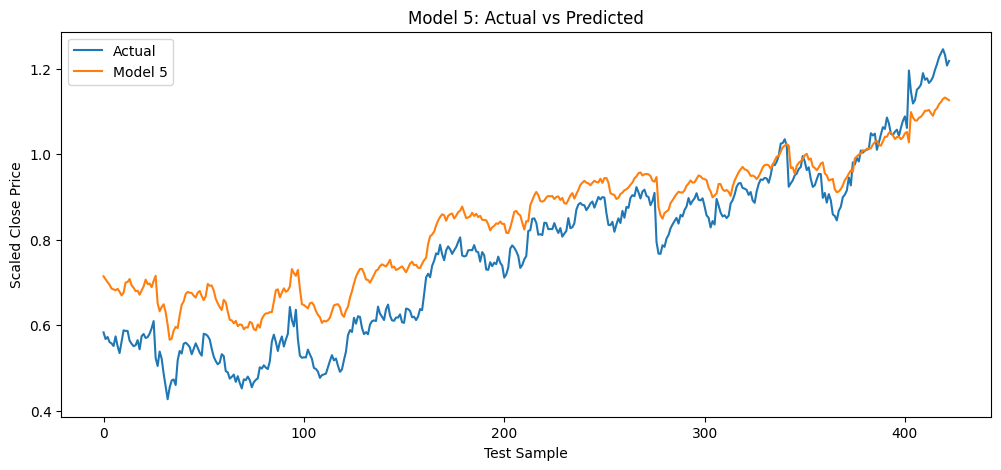

In [162]:
plt.figure(figsize=(12,5))

plt.plot(
    all_actuals_5,
    label="Actual"
)



plt.plot(
    all_predictions_5,
    label="Model 5"
)

plt.title("Model 5: Actual vs Predicted")
plt.xlabel("Test Sample")
plt.ylabel("Scaled Close Price")
plt.legend()

plt.show()


Final comparison of all 5 models

In [163]:
results = {
    "Model 1": {
        "MSE": mse_1,
        "MAE": mae_1_check,
        "RMSE": rmse_1_check
    },

    "Model 2": {
        "MSE": mse_2,
        "MAE": mae_2,
        "RMSE": rmse_2
    },

    "Model 3": {
        "MSE": mse_3,
        "MAE": mae_3,
        "RMSE": rmse_3
    },

    "Model 4": {
        "MSE": mse_4,
        "MAE": mae_4,
        "RMSE": rmse_4
    },

    "Model 5": {
        "MSE": mse_5,
        "MAE": mae_5,
        "RMSE": rmse_5
    }
}

for model_name, metrics in results.items():

    print(model_name)

    print(f"  MSE:  {metrics['MSE']:.6f}")
    print(f"  MAE:  {metrics['MAE']:.6f}")
    print(f"  RMSE: {metrics['RMSE']:.6f}")

    print()

Model 1
  MSE:  0.044326
  MAE:  0.180941
  RMSE: 0.210538

Model 2
  MSE:  0.019831
  MAE:  0.108914
  RMSE: 0.140824

Model 3
  MSE:  0.006824
  MAE:  0.070618
  RMSE: 0.082608

Model 4
  MSE:  0.023767
  MAE:  0.133033
  RMSE: 0.154164

Model 5
  MSE:  0.008119
  MAE:  0.079902
  RMSE: 0.090105



And finally, one combined plot

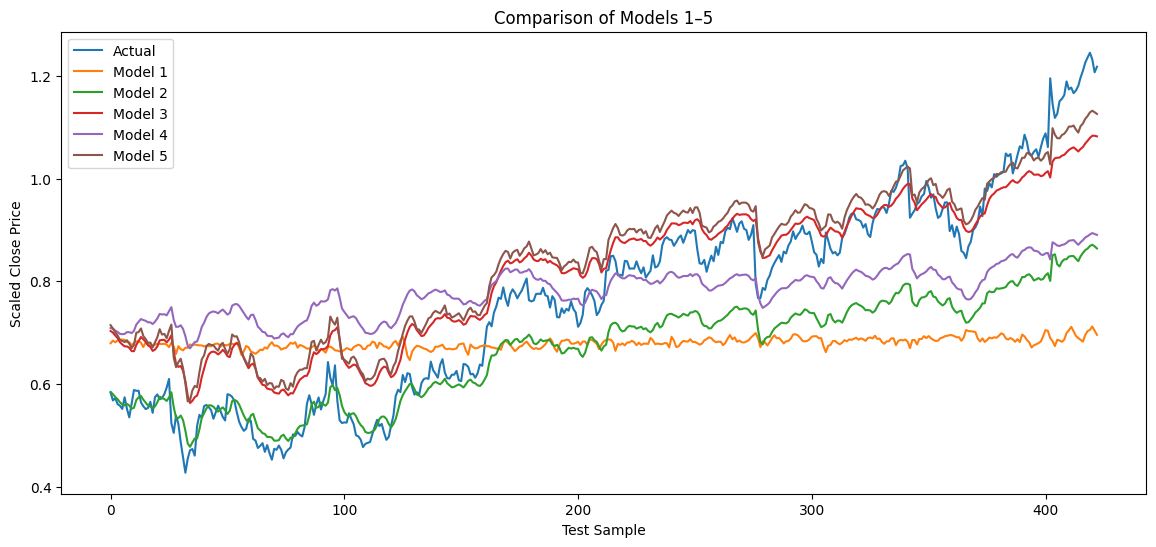

In [164]:
plt.figure(figsize=(14, 6))

plt.plot(
    all_actuals_3,
    label="Actual"
)

plt.plot(
    all_predictions,
    label="Model 1"
)

plt.plot(
    all_predictions_2,
    label="Model 2"
)

plt.plot(
    all_predictions_3,
    label="Model 3"
)

plt.plot(
    all_predictions_4,
    label="Model 4"
)

plt.plot(
    all_predictions_5,
    label="Model 5"
)

plt.title("Comparison of Models 1–5")
plt.xlabel("Test Sample")
plt.ylabel("Scaled Close Price")
plt.legend()

plt.show()